# 5. Furnace cooling vs air cooling, category by category

Every catalogue grade that forms ferrite + pearlite on slow cooling is taken through both routes. The table
gives, per category, the microstructure that forms and the median change in properties on air cooling
(25 mm bar).

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3g}")
R = ROOT / "results"; FIG = ROOT / "figures"
def fig(name, width=1000):
    display(Image(filename=str(FIG / f"{name}.png"), width=width))

In [2]:
s = pd.read_csv(R / "s05_category_summary.csv")
s[["category", "grades", "FC_regime_mode", "AC25_regime_mode", "FC_pearlite_mean", "AC25_pearlite_mean",
   "AC25_bainite_martensite_mean", "UTS_MPa_FC_median", "UTS_MPa_AC25_median", "UTS_MPa_delta_median",
   "YS_MPa_delta_median", "El_pct_delta_median", "uniformEl_FC_median", "uniformEl_AC25_median"]]

,category,grades,FC_regime_mode,AC25_regime_mode,FC_pearlite_mean,AC25_pearlite_mean,AC25_bainite_martensite_mean,UTS_MPa_FC_median,UTS_MPa_AC25_median,UTS_MPa_delta_median,YS_MPa_delta_median,El_pct_delta_median,uniformEl_FC_median,uniformEl_AC25_median
0,Low-carbon steel,85,F+P,F+P,0.153,0.153,0,405,447,40.4,36.8,0.409,18.4,18.6
1,Medium-carbon steel,21,F+P,F+P,0.541,0.541,0,538,643,105,48.8,-3.27,14.5,12.8
2,High-carbon steel,20,F+P,F+P,0.935,0.94,0,617,920,307,132,-8.42,11.5,6.98
3,Free-machining steel,18,F+P,F+P,0.342,0.281,0.111,495,577,73,40.1,-1.17,15.9,15.1
4,C-Mn / Mn steel,55,F+P,F+P,0.422,0.358,0.107,490,568,79.5,35.5,-1.52,16.1,15.4
5,Cr / Cr-V steel,19,F+P,F+P,0.641,0.575,0.0784,607,807,217,140,-4.13,12.9,10.8
6,Mo / Cr-Mo steel,17,F+P,F+P,0.543,0.248,0.427,610,736,176,110,-5.4,13.4,9.74
7,Ni-Cr-Mo / Ni steel,34,F+P,F+P+B,0.42,0.173,0.497,582,767,163,66.9,-6.43,14.5,11.3
8,Si-Mn spring steel,2,F+P,F+P,0.672,0.672,0,779,890,111,38.9,-4.89,11.3,8.8


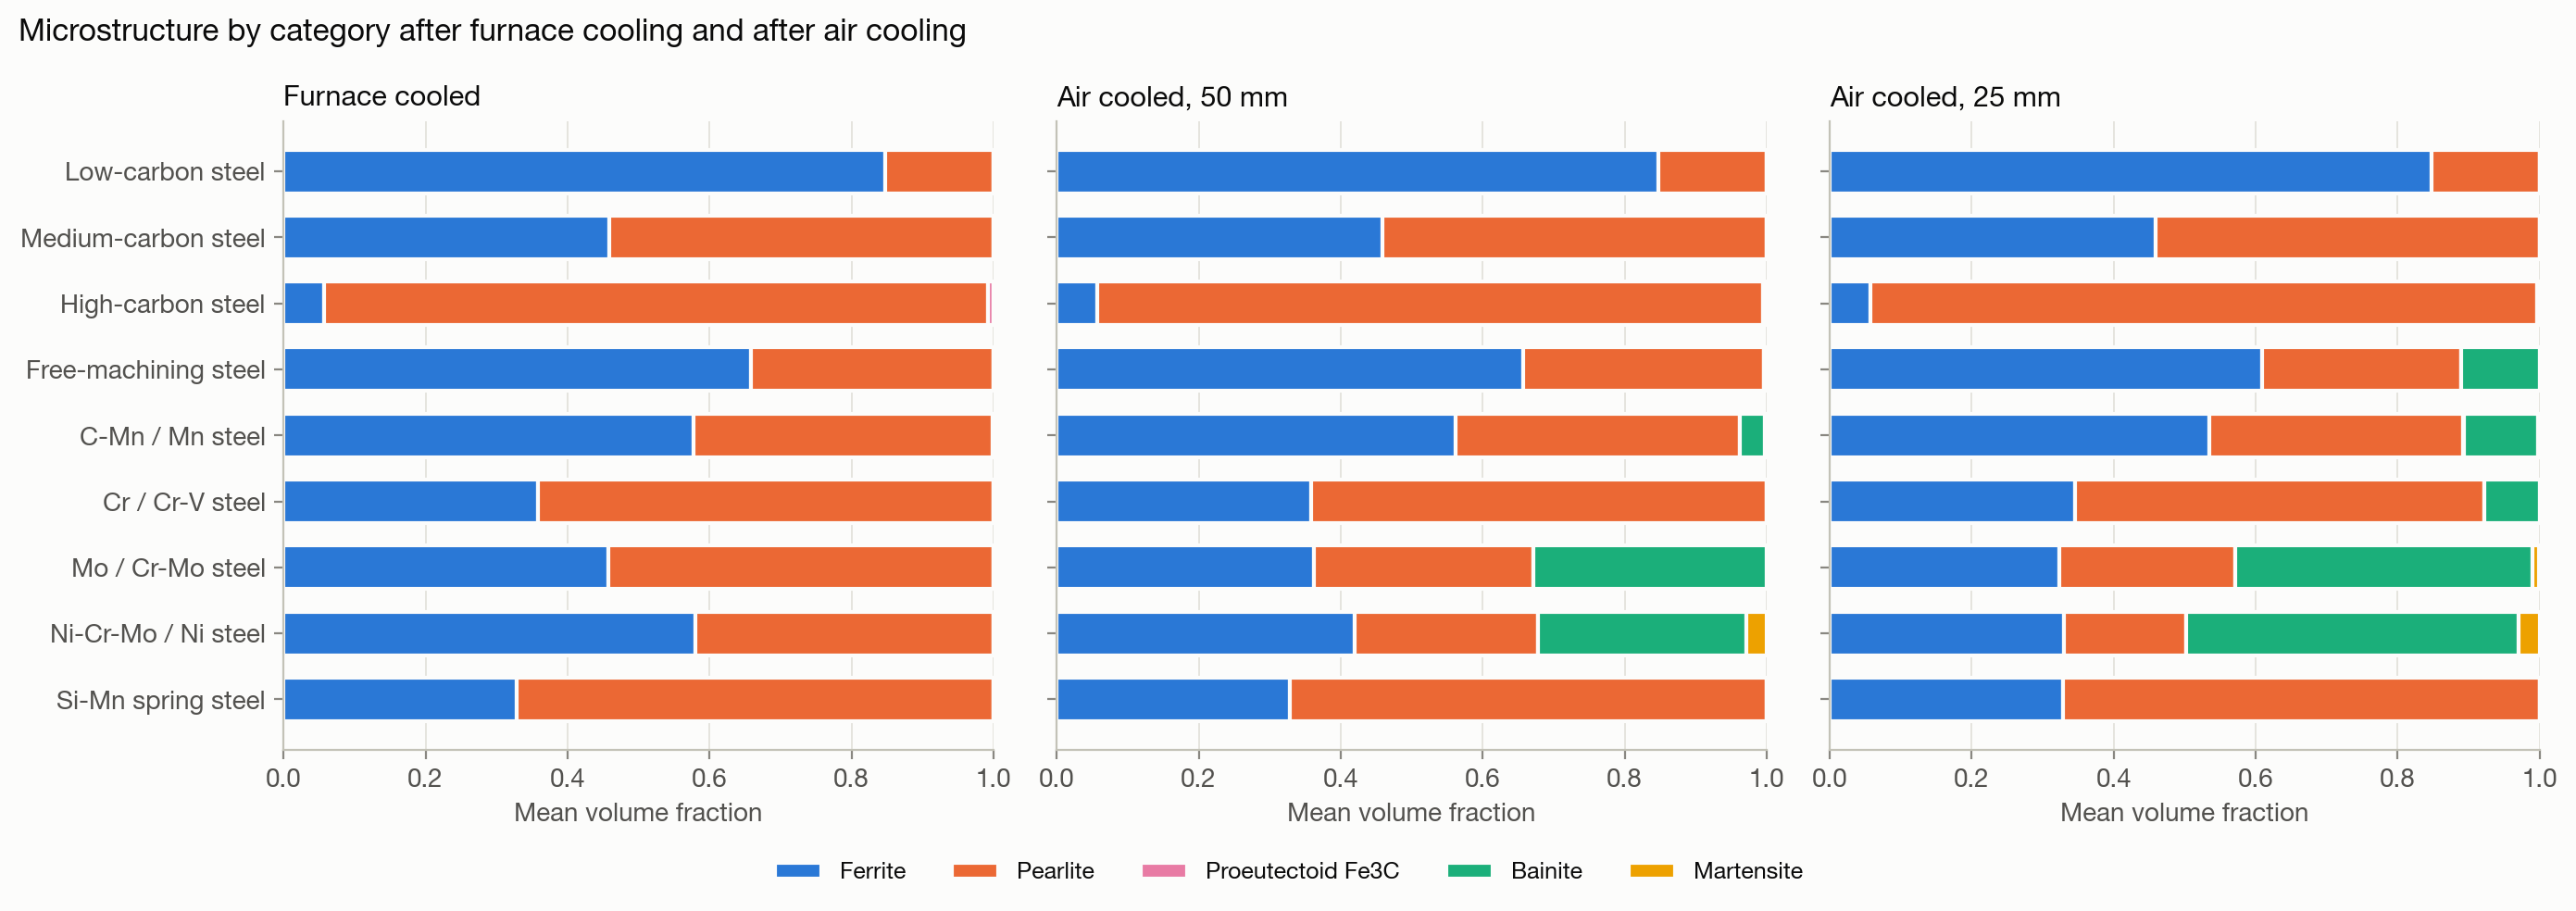

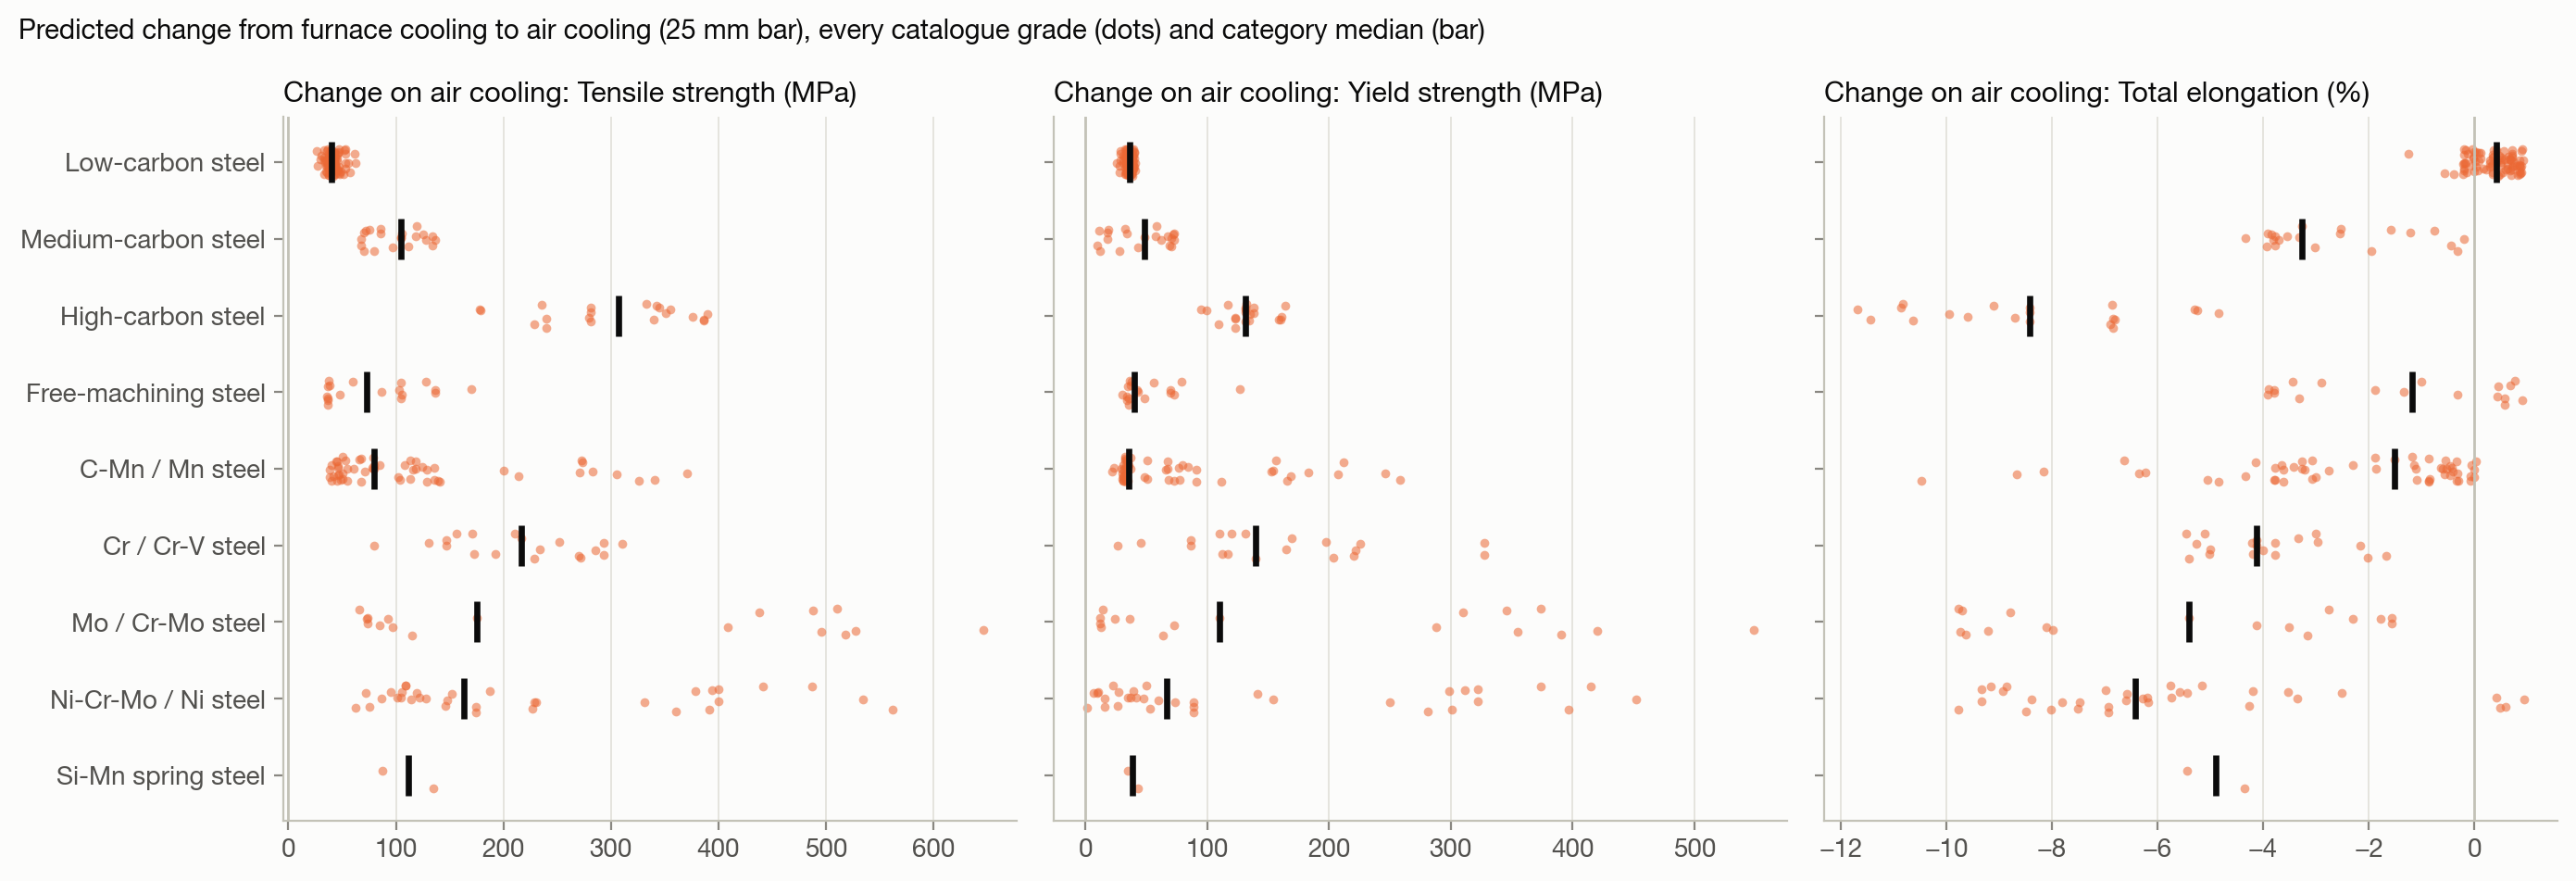

In [3]:
fig("fig19_category_microstructures"); fig("fig18_category_route_effects")

## Why air cooling is stronger: faster cooling or hotter austenitisation?
Normalising is done about 60 °C hotter than annealing. Air cooling a bar from the annealing temperature
separates the two: almost all of the gain comes from the faster cooling. The impact transition temperature
(Pickering, a toughness indicator) falls on air cooling because the ferrite grains are finer.

In [4]:
s[["category", "UTS_MPa_delta_median", "UTS_MPa_delta_cooling_median", "UTS_MPa_delta_temperature_median",
   "FC_d_alpha_um_median", "AC25_d_alpha_um_median", "ITT_FC_median_C", "ITT_AC25_median_C", "DI_mm_median"]]

,category,UTS_MPa_delta_median,UTS_MPa_delta_cooling_median,UTS_MPa_delta_temperature_median,FC_d_alpha_um_median,AC25_d_alpha_um_median,ITT_FC_median_C,ITT_AC25_median_C,DI_mm_median
0,Low-carbon steel,40.4,46.9,-5.61,38.4,18.1,-6.96,-32.6,10.1
1,Medium-carbon steel,105,111,-4.31,18.8,11.7,56.6,34.2,32.3
2,High-carbon steel,307,308,-7.17,18.8,11.3,152,128,40.5
3,Free-machining steel,73,86.2,-5.44,18.9,12.1,12.9,-33.7,30.1
4,C-Mn / Mn steel,79.5,84.2,-7.76,18.8,12.1,13.9,-21,33.3
5,Cr / Cr-V steel,217,220,-5.42,18.8,11.5,82,57,69.9
6,Mo / Cr-Mo steel,176,165,-3.85,18.8,11.8,63.5,10.7,70.6
7,Ni-Cr-Mo / Ni steel,163,169,-6.6,18.8,12,18,-16.8,67.3
8,Si-Mn spring steel,111,125,-13.7,19.2,12.6,164,145,87.1


## How much of the error is the unknown heat composition?
The training data give one value per grade at the nominal composition. Varying each grade's composition
inside its own specification range moves the prediction by about this much, a floor under the error of any
model of nominal compositions.

In [5]:
pd.read_csv(R / "s05_composition_noise_floor.csv")

,route,target,grades,heats_per_grade,median_sd,rms_sd,max_sd
0,FC,UTS_MPa,33,60,18.2,20,43.1
1,FC,YS_MPa,33,60,8.66,11.9,24.6
2,FC,El_pct,33,60,0.666,0.771,1.35
3,FC,HB,33,60,5.81,6.44,13.7
4,AC,UTS_MPa,33,60,32.2,52.8,121
5,AC,YS_MPa,33,60,24.6,36.3,79.1
6,AC,El_pct,33,60,0.977,1.11,1.94
7,AC,HB,33,60,8.65,13.1,26.7


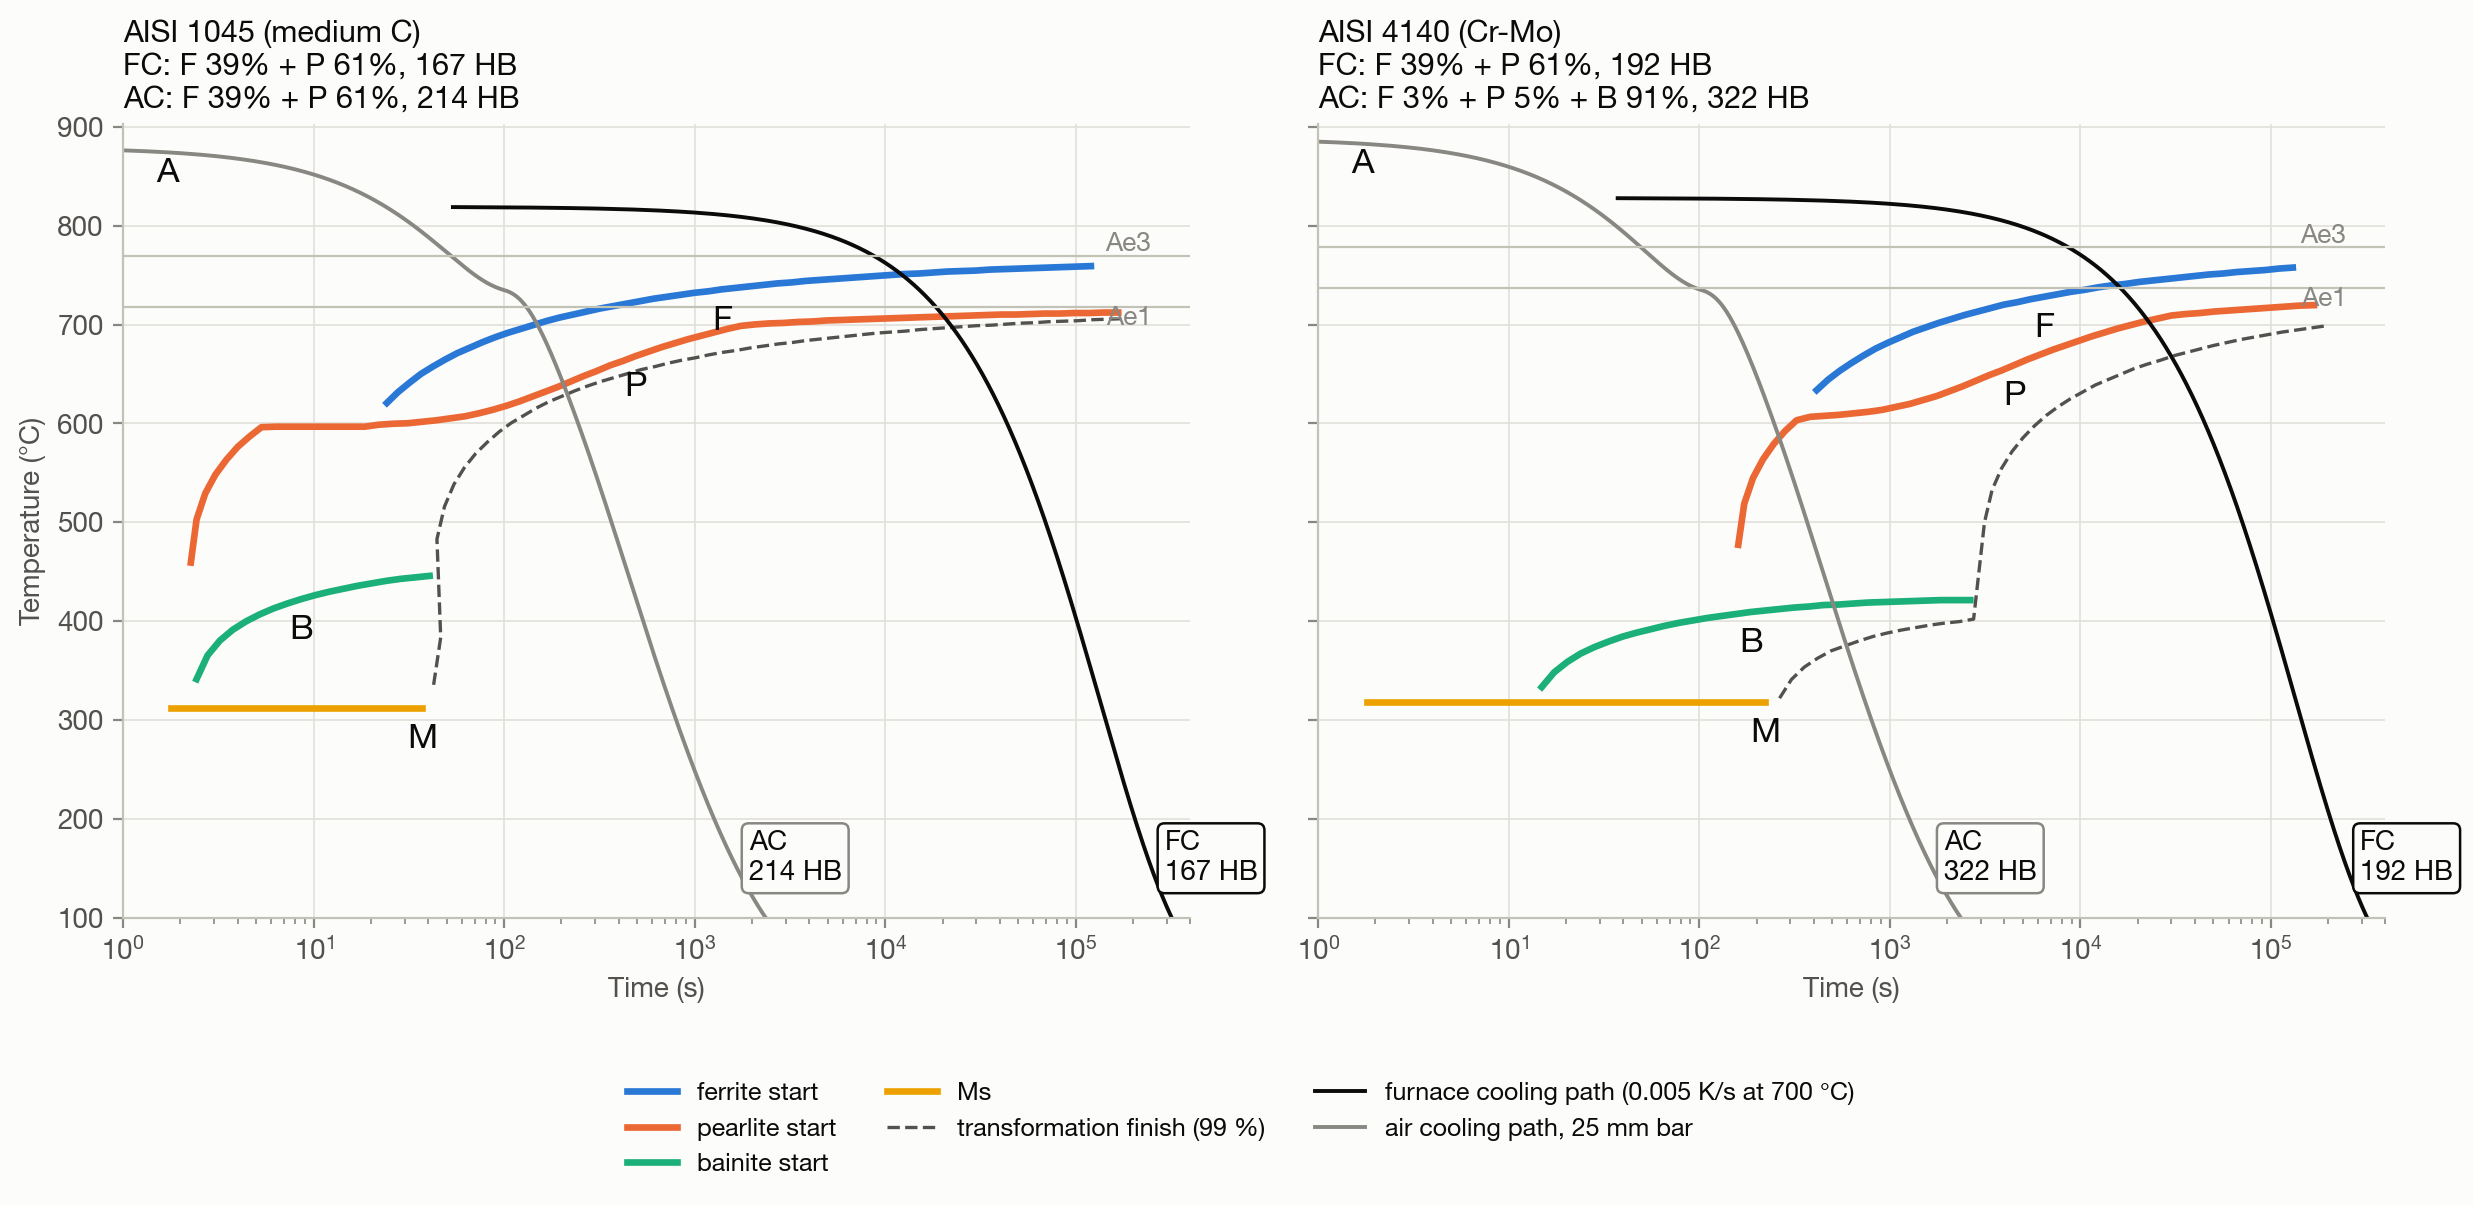

In [6]:
fig("fig09b_cct_1045_vs_4140", 900)

## Plain-carbon steels across the carbon range
The classic fine-pearlite versus coarse-pearlite chart, regenerated with 90 % intervals. Near the eutectoid
the furnace-cooled curve flattens because the handbook's annealed 1080 (615 MPa, 24.7 % elongation) is softer
and more ductile than its annealed 1060; that row looks partly spheroidised, and we flag it as suspect rather
than explain it.

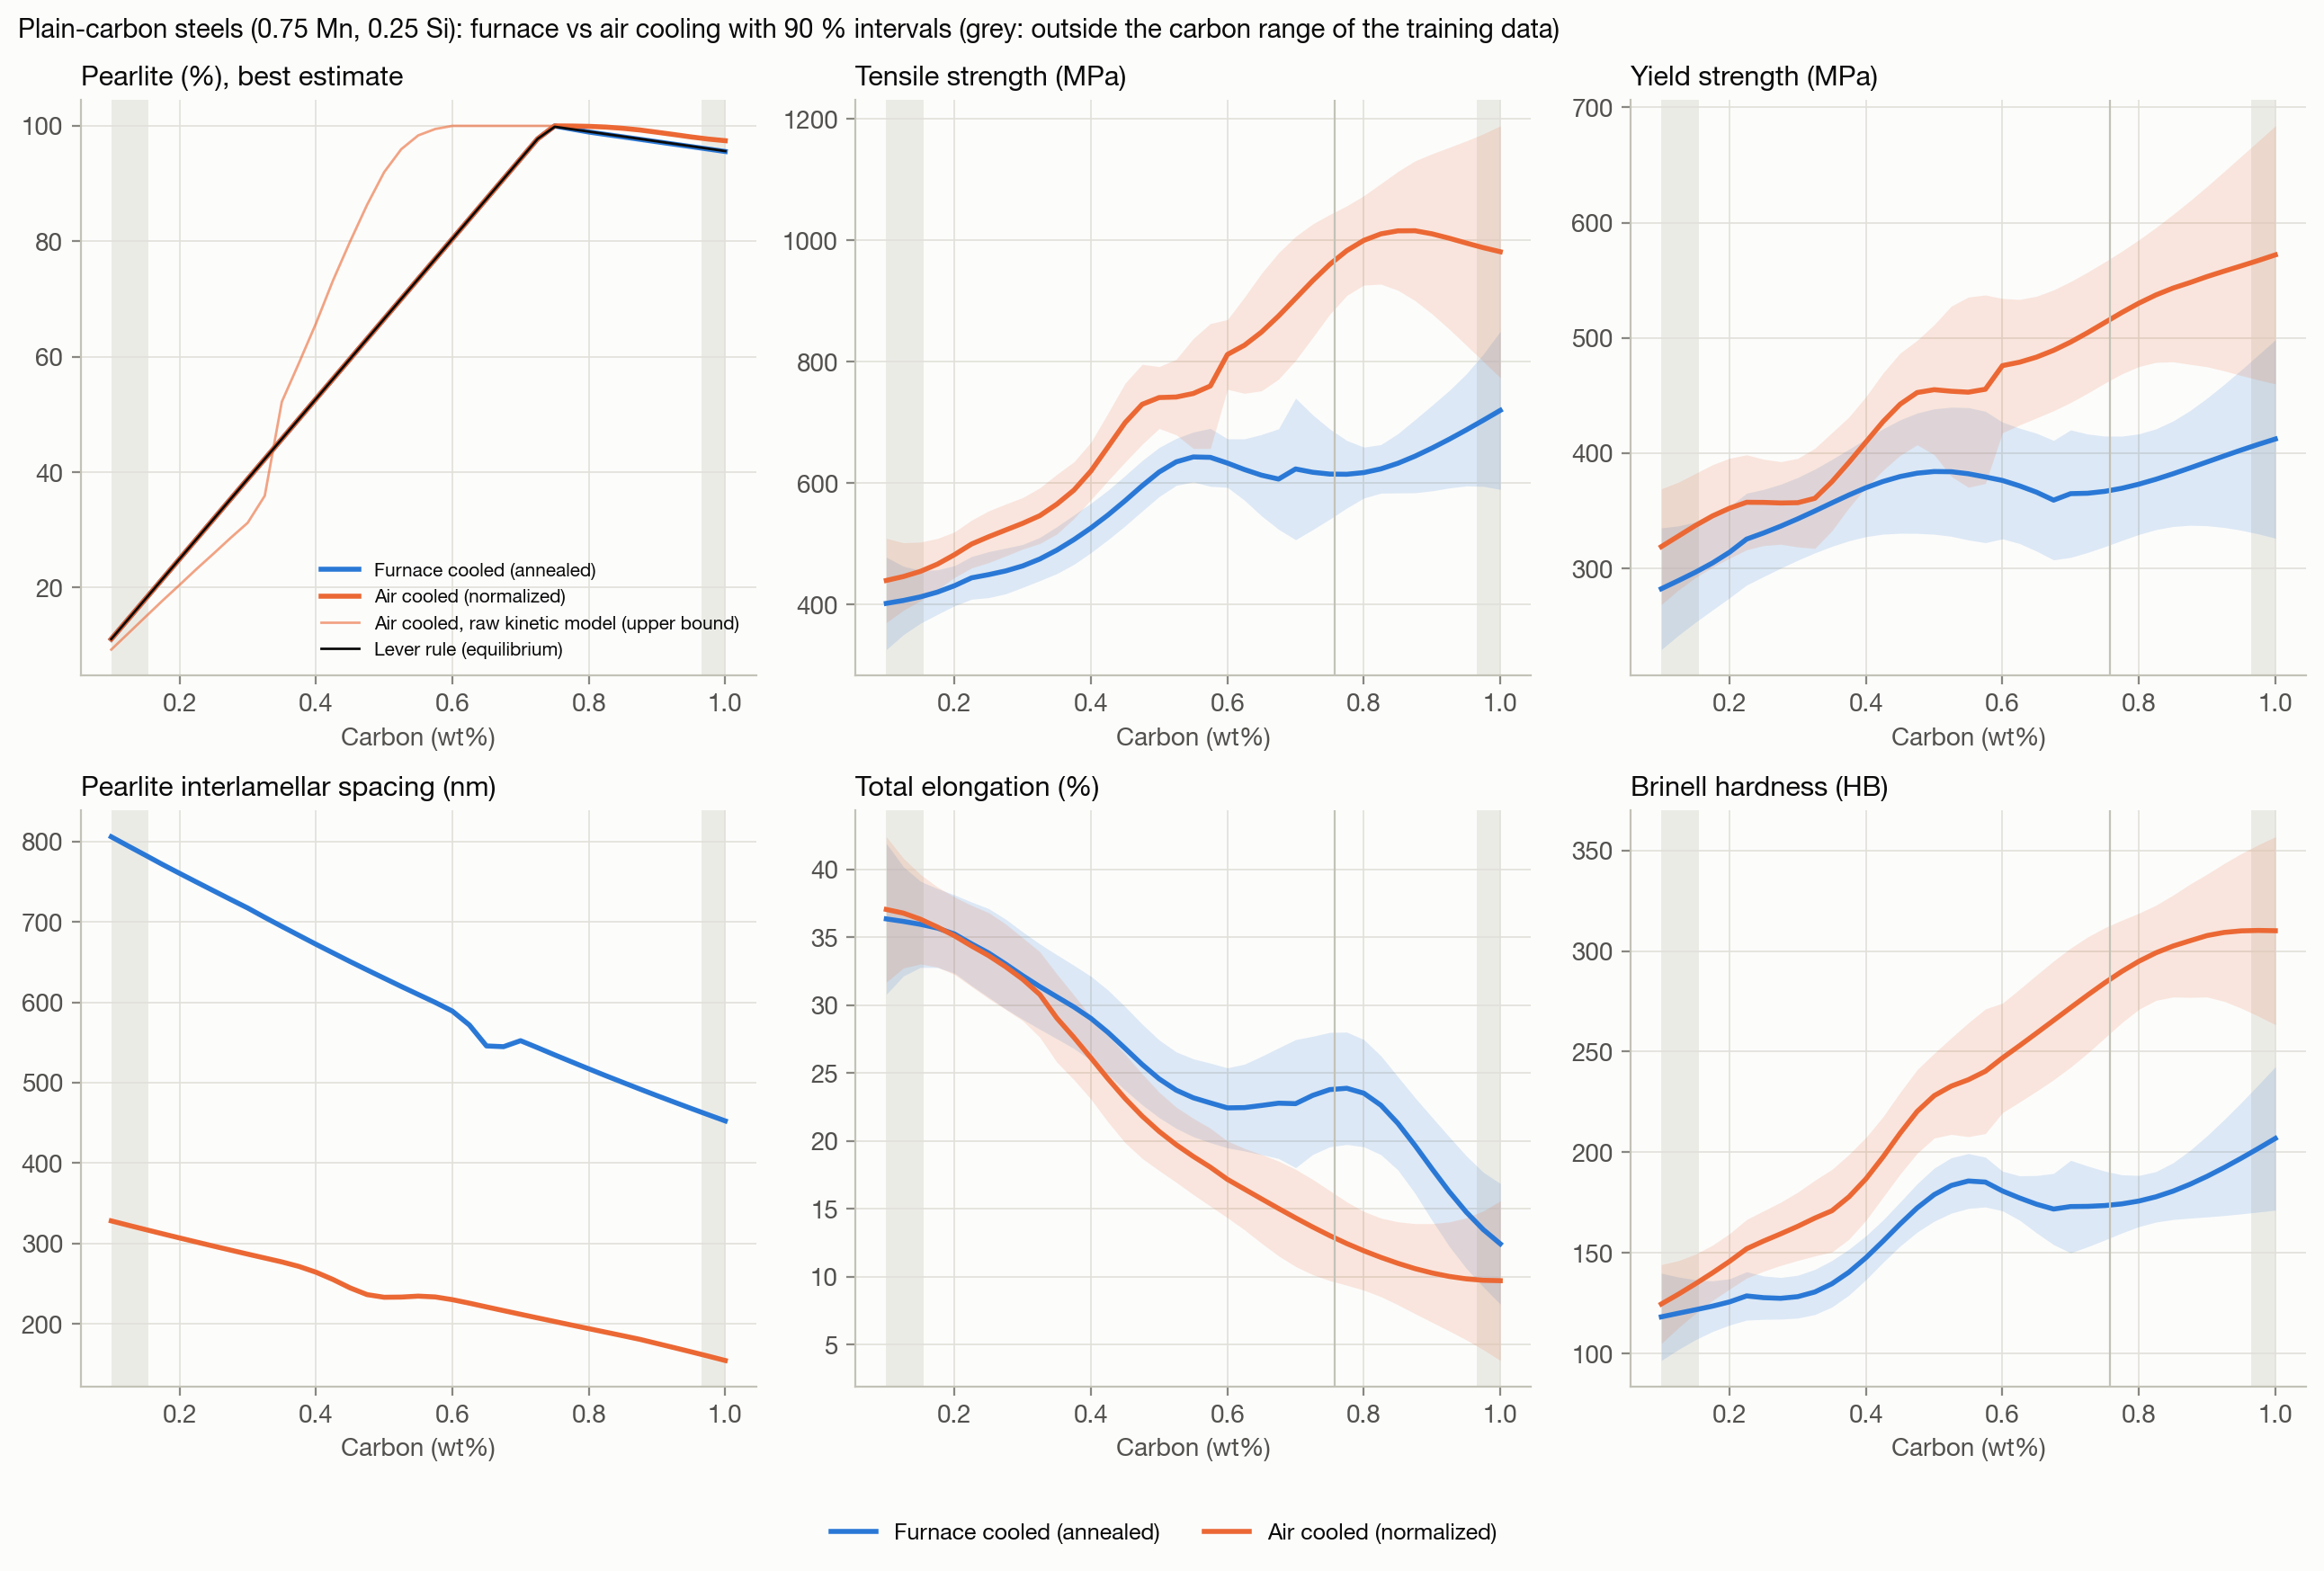

In [7]:
fig("fig16_carbon_sweep_fc_vs_ac")

## Section size: air cooling a thick bar approaches furnace cooling

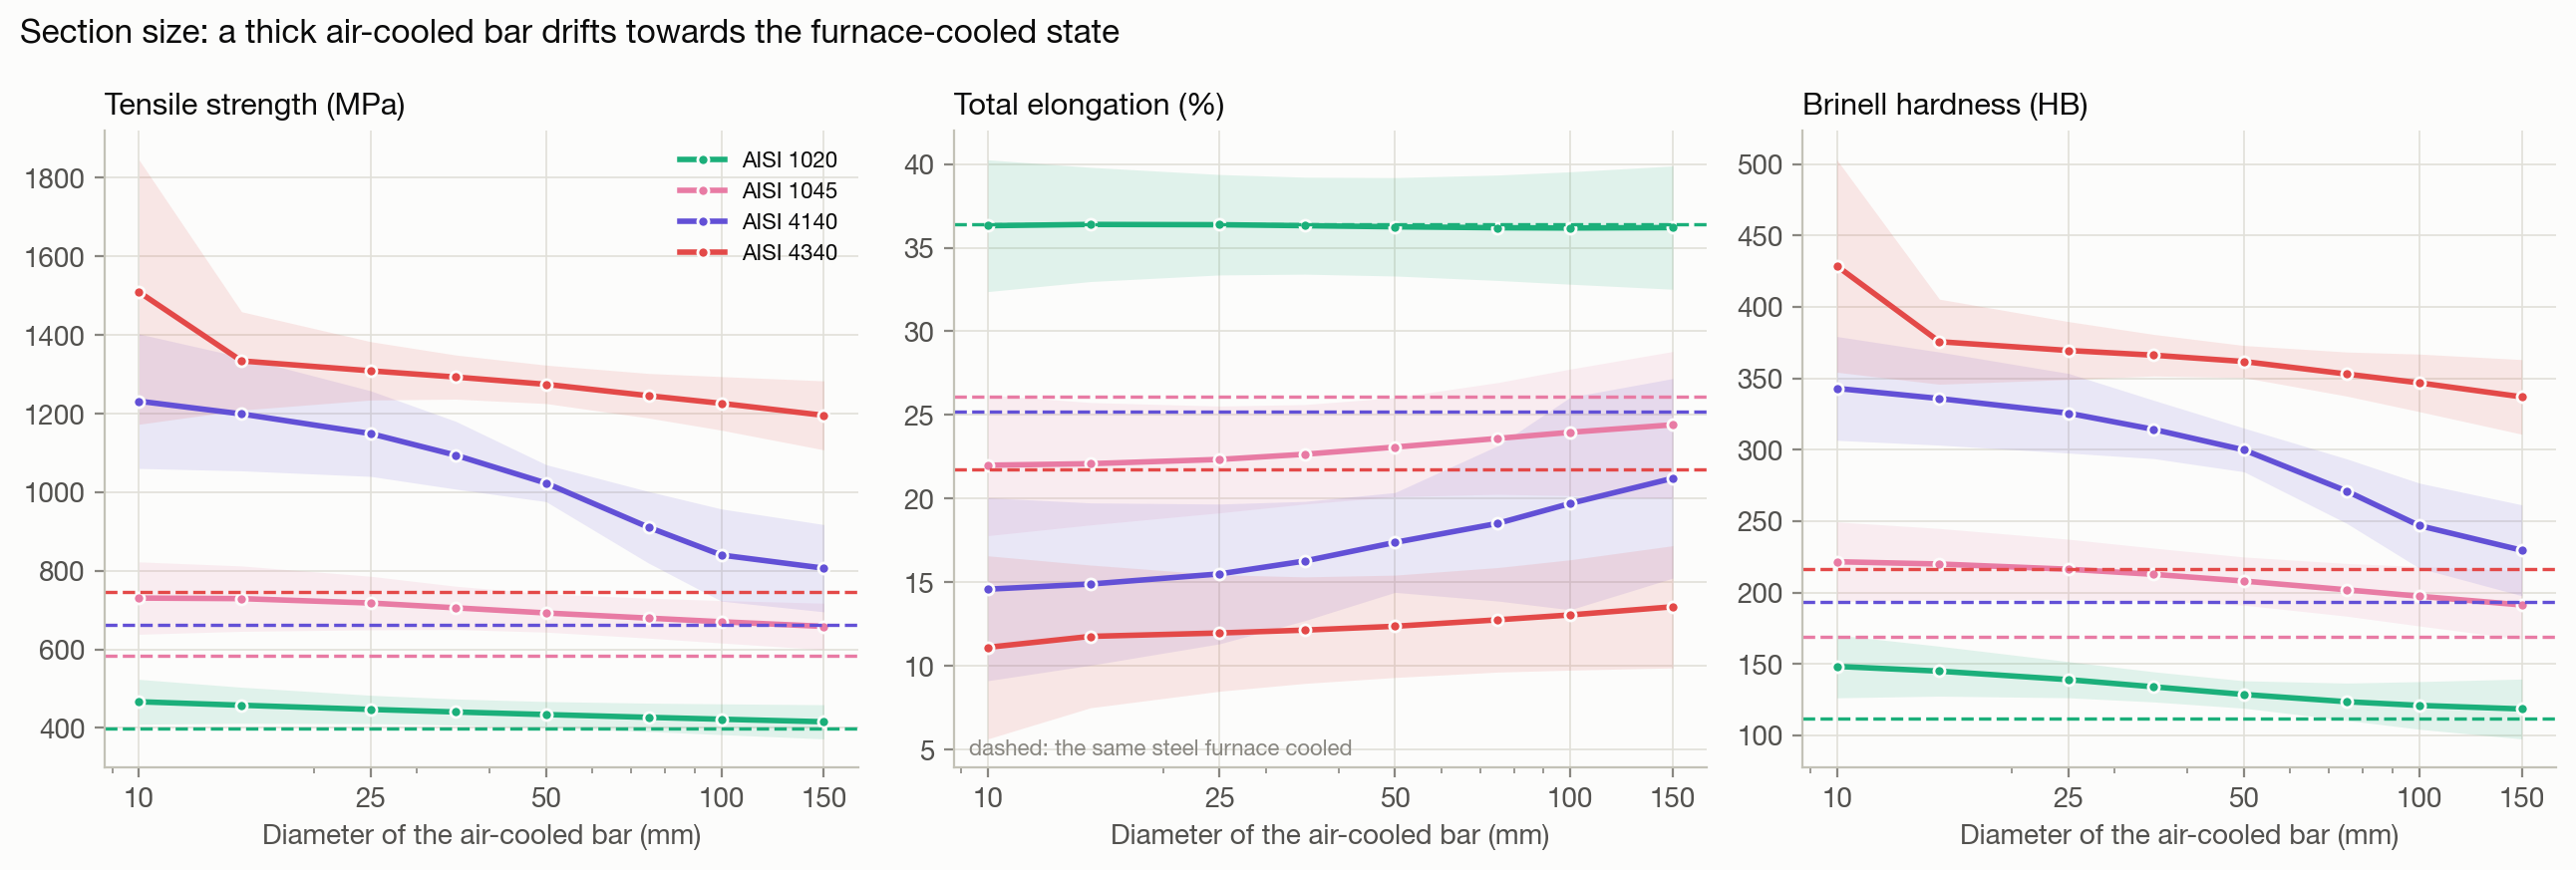

In [8]:
fig("fig17_section_size_effect")

## Try it: one steel, both routes

In [9]:
from steelml.predictor import SteelPredictor
sp = SteelPredictor.load()
out = sp.what_if({"C": 0.45, "Mn": 0.75, "Si": 0.25})
cols = ["route", "F_best", "P_best", "B_best", "M_best", "S0_um", "YS_MPa_pred", "YS_MPa_lo90", "YS_MPa_hi90",
        "UTS_MPa_pred", "UTS_MPa_lo90", "UTS_MPa_hi90", "El_pct_pred", "uniform_El_est_pct", "HB_pred", "in_domain"]
out[cols]

,route,F_best,P_best,B_best,M_best,S0_um,YS_MPa_pred,YS_MPa_lo90,YS_MPa_hi90,UTS_MPa_pred,UTS_MPa_lo90,UTS_MPa_hi90,El_pct_pred,uniform_El_est_pct,HB_pred,in_domain
0,FC,0.404,0.596,0,0,0.651,380,331,429,571,530,612,26.8,13.6,164,True
1,AC,0.404,0.596,0,0,0.245,442,398,487,700,635,765,23.1,11.8,209,True
